In [2]:
# selected links with best metrics 
selected_links = ['ac-to', 'es-ce', 'es-pr', 'go-sp', 'ms-to', 'sc-to']

In [ ]:
# copy "selected links"
from pathlib import Path
import shutil

SRC_DIR = Path("../results_sbrc_26/treated/treated/bbr")
DST_DIR = Path("./choosen_treated_datasets")
DST_DIR.mkdir(parents=True, exist_ok=True)

for file_path in SRC_DIR.iterdir():
    if not file_path.is_file():
        continue

    filename = file_path.name.lower()

    # Verifica se o nome do arquivo começa com algum dos links selecionados
    for link in selected_links:
        if filename.startswith(f"{link}_"):
            shutil.copy2(file_path, DST_DIR / file_path.name)
            print(f"Copiado: {file_path.name}")
            break


Copiado: ac-to_bbr_interval_0.csv
Copiado: es-ce_bbr_interval_0.csv
Copiado: es-pr_bbr_interval_0.csv
Copiado: go-sp_bbr_interval_0.csv
Copiado: ms-to_bbr_interval_0.csv
Copiado: sc-to_bbr_interval_0.csv


In [ ]:
# aggregate by 6h for analysis
from pathlib import Path
import pandas as pd
import numpy as np

IN_DIR = Path("./choosen_treated_datasets")
OUT_DIR = Path("./choosen_treated_datasets_6h")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TIME_COL = "Data"   
FREQ = "6H"        

for csv_path in sorted(IN_DIR.glob("*.csv")):
    try:
        df = pd.read_csv(csv_path)

        if TIME_COL not in df.columns:
            raise ValueError(f"Coluna '{TIME_COL}' não encontrada. Colunas: {list(df.columns)}")

        df[TIME_COL] = pd.to_datetime(df[TIME_COL], format="%Y-%m-%d %H:%M:%S", errors="coerce")
        df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL).set_index(TIME_COL)

        num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        if not num_cols:
            raise ValueError("Não há colunas numéricas para agregar (verifique o CSV).")

        agg = df[num_cols].resample(FREQ).mean()

        full_idx = pd.date_range(start=agg.index.min(), end=agg.index.max(), freq=FREQ)
        agg = agg.reindex(full_idx)

        agg = agg.fillna(-1)

        agg = agg.reset_index().rename(columns={"index": TIME_COL})

        out_path = OUT_DIR / f"{csv_path.stem}_6h.csv"
        agg.to_csv(out_path, index=False)

        print(f"OK: {csv_path.name} -> {out_path.name}")

    except Exception as e:
        print(f"ERRO em {csv_path.name}: {e}")

OK: ac-to_bbr_interval_0.csv -> ac-to_bbr_interval_0_6h.csv
OK: es-ce_bbr_interval_0.csv -> es-ce_bbr_interval_0_6h.csv
OK: es-pr_bbr_interval_0.csv -> es-pr_bbr_interval_0_6h.csv
OK: go-sp_bbr_interval_0.csv -> go-sp_bbr_interval_0_6h.csv
OK: ms-to_bbr_interval_0.csv -> ms-to_bbr_interval_0_6h.csv
OK: sc-to_bbr_interval_0.csv -> sc-to_bbr_interval_0_6h.csv


C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\324762482.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = df[num_cols].resample(FREQ).mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\324762482.py:28: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(start=agg.index.min(), end=agg.index.max(), freq=FREQ)
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\324762482.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  agg = df[num_cols].resample(FREQ).mean()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\324762482.py:28: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  full_idx = pd.date_range(start=agg.index.min(), end=agg.index.max(), freq=FREQ)
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\324762482.py:26: FutureWarning: 'H' is d

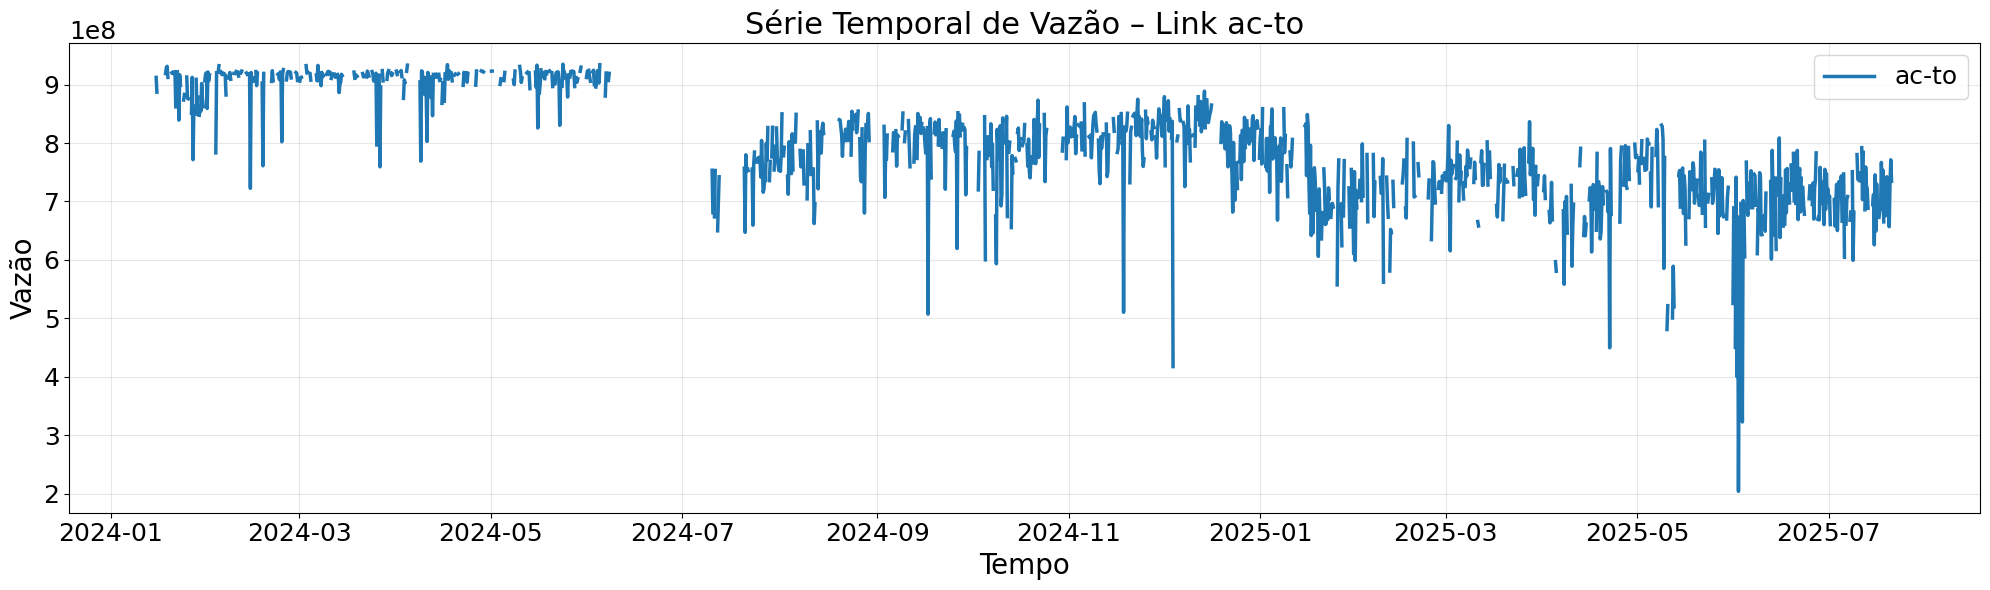

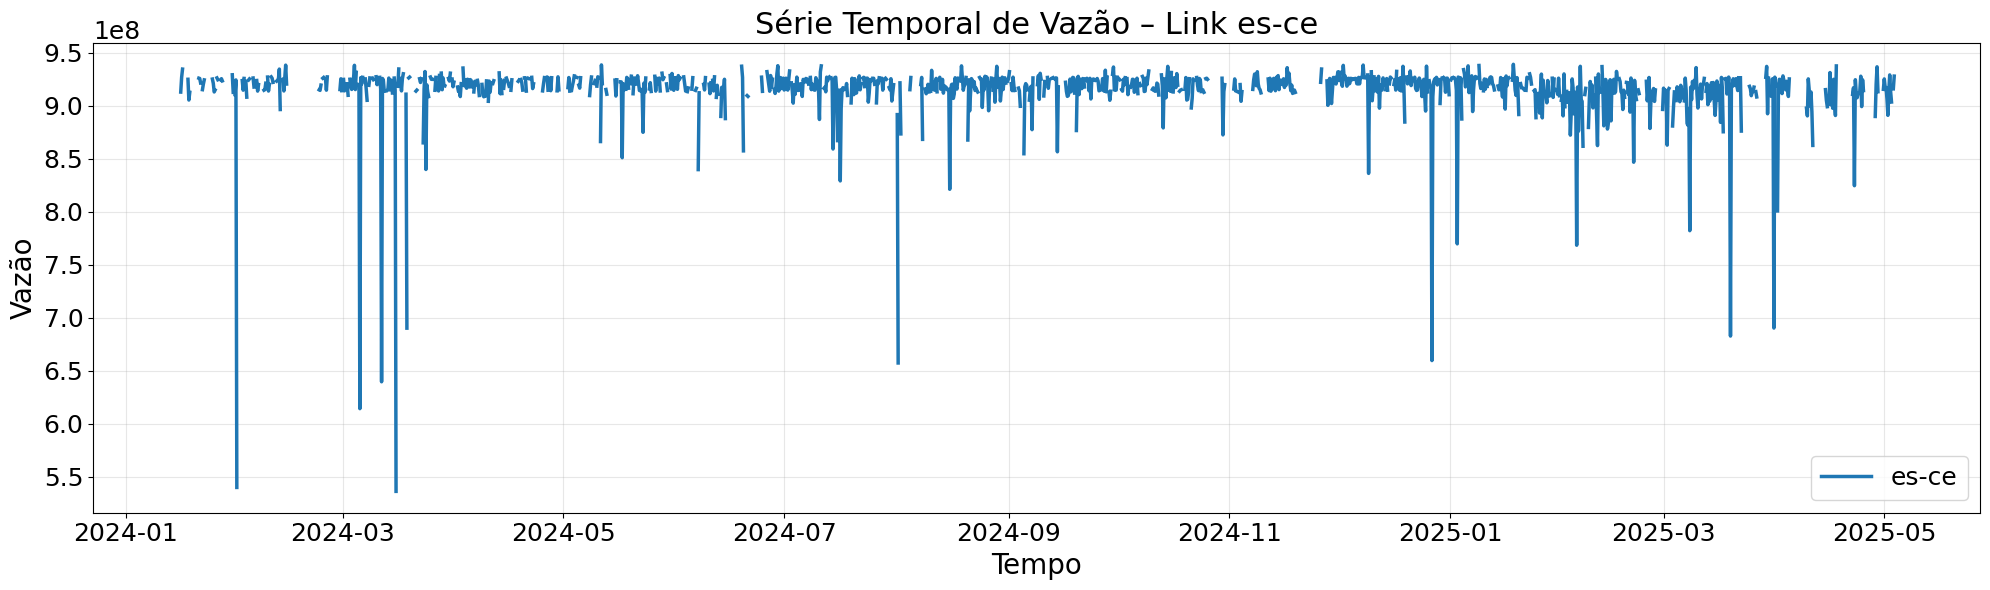

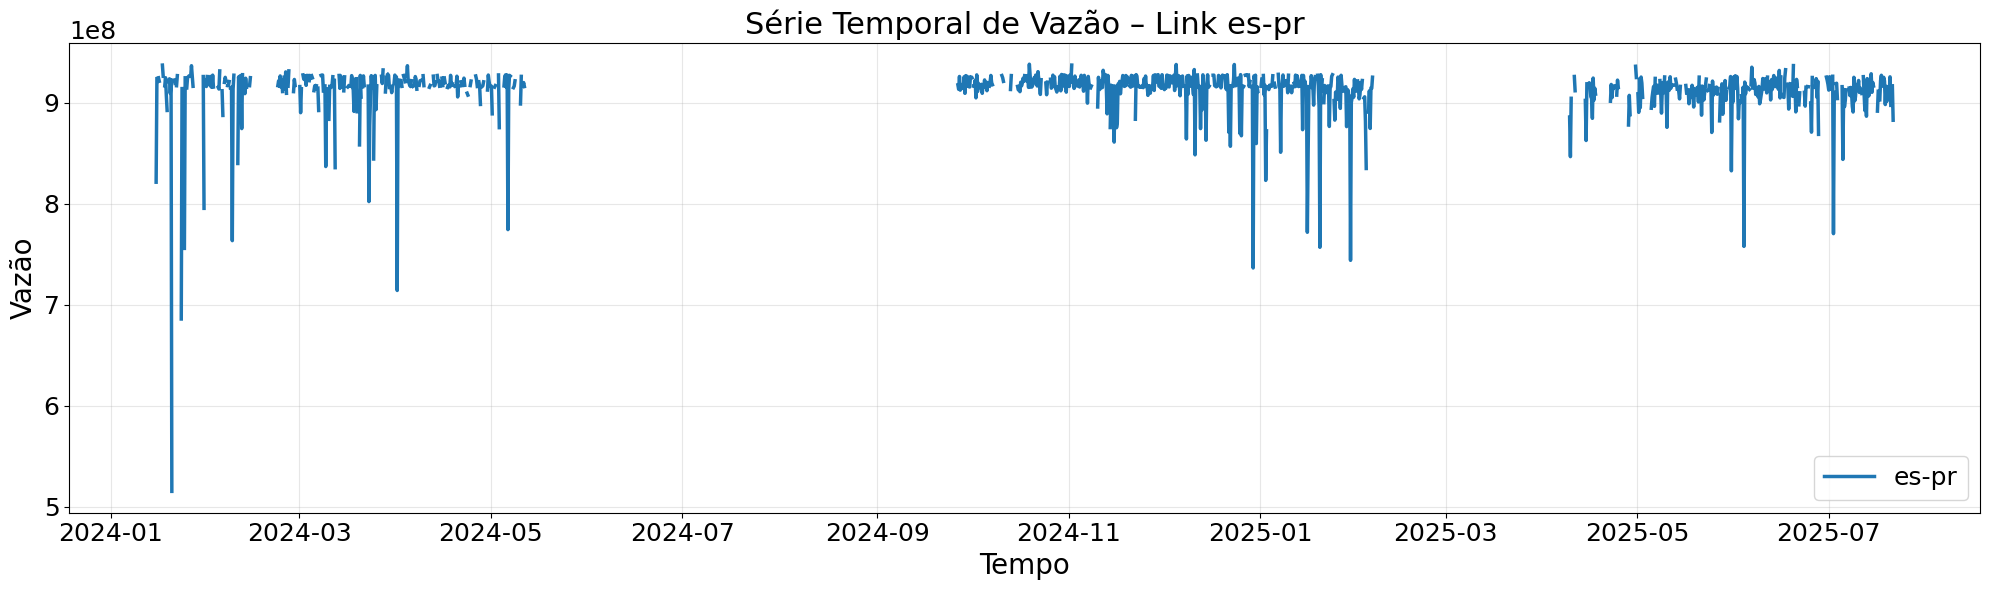

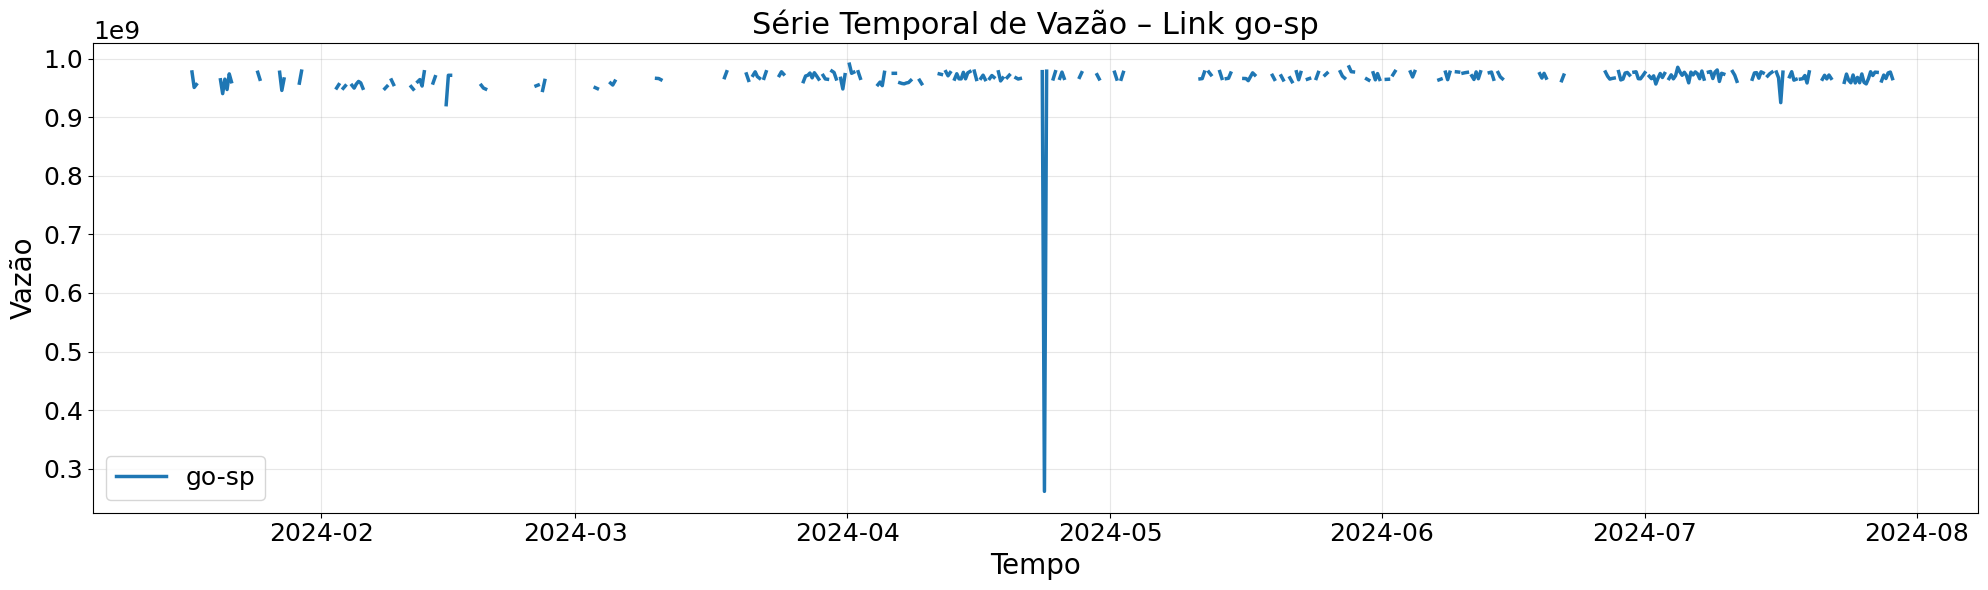

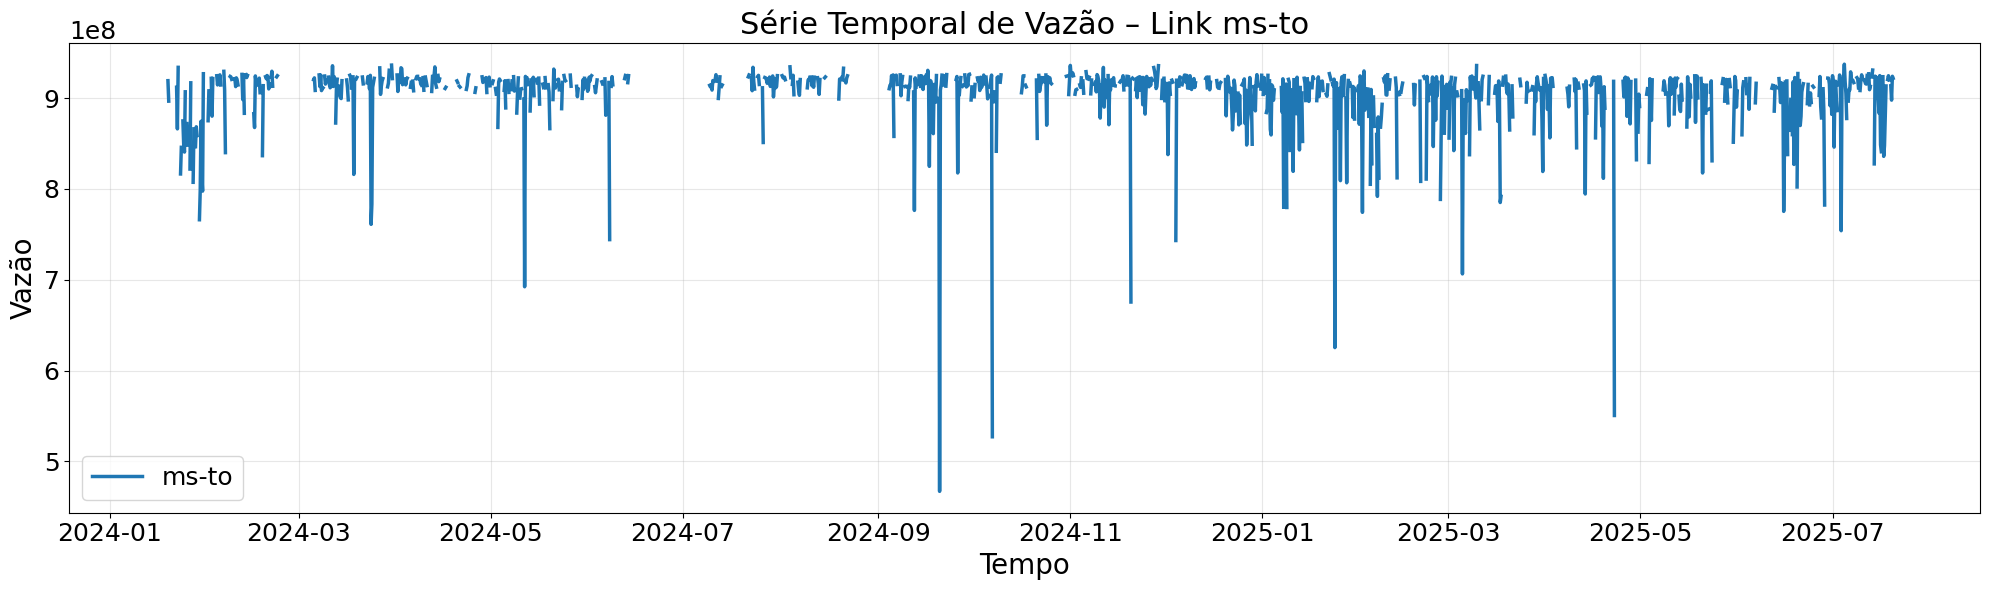

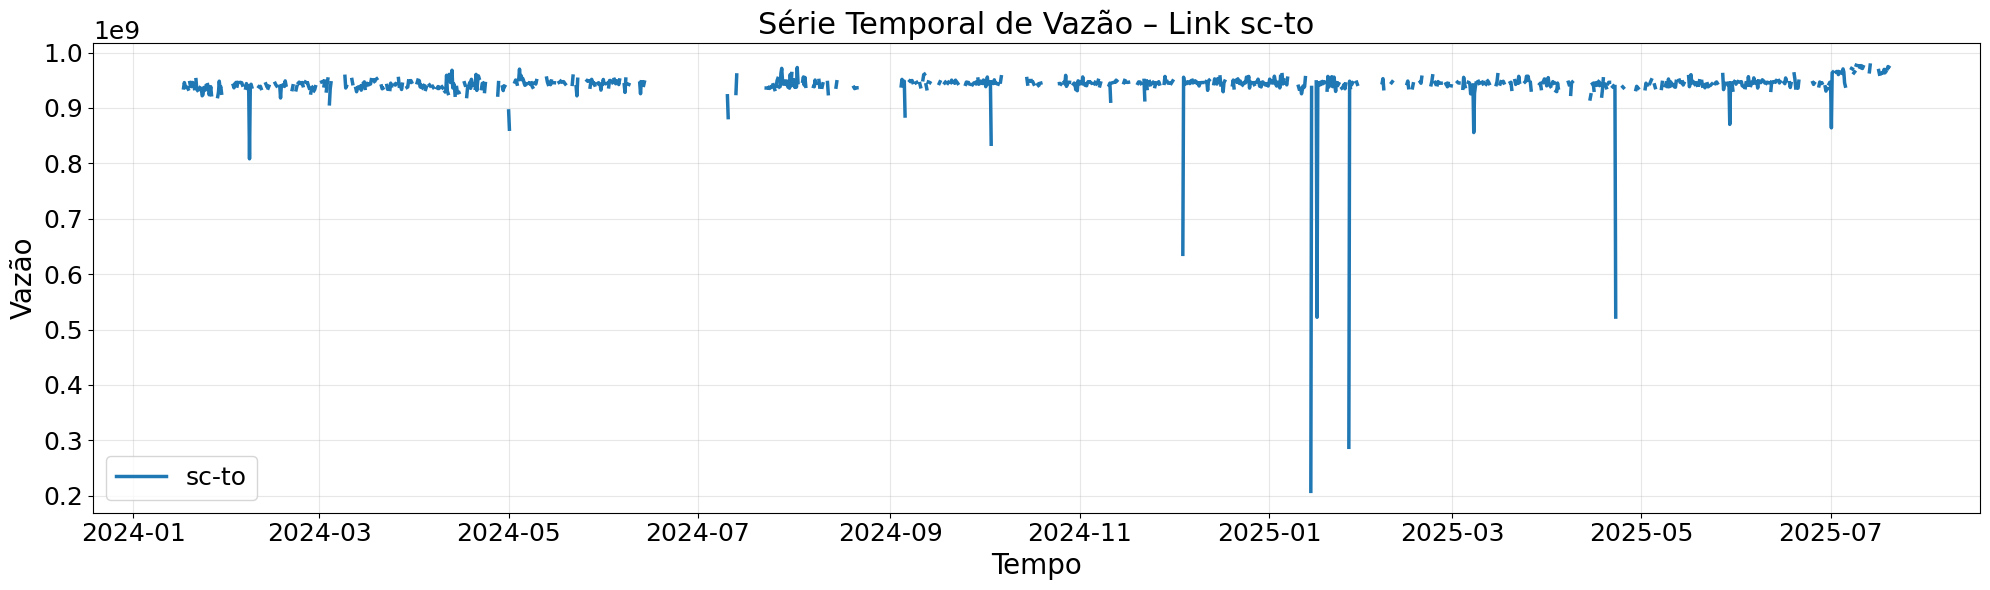

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("./choosen_treated_datasets_6h")
TIME_COL = "Data"
Y_COL = "Vazao"

def find_csv_for_link(link: str, data_dir: Path) -> Path:
    matches = sorted(
        [p for p in data_dir.glob("*.csv")
         if p.stem.lower().startswith(link.lower() + "_")]
    )
    if not matches:
        matches = sorted(
            [p for p in data_dir.glob("*.csv")
             if (link.lower() + "_") in p.stem.lower()]
        )
    if not matches:
        raise FileNotFoundError(f"Não achei CSV para o link '{link}'")
    return matches[0]

# =========================
# CONFIGURAÇÕES VISUAIS
# =========================
FIGSIZE = (20, 6)

TITLE_SIZE = 22
LABEL_SIZE = 20
TICK_SIZE = 18
LEGEND_SIZE = 18
LINE_WIDTH = 2.5

plt.rcParams.update({
    "axes.titlesize": TITLE_SIZE,
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
})

# =========================
# PLOTS (UM POR FIGURA)
# =========================
for link in selected_links:

    csv_path = find_csv_for_link(link, DATA_DIR)
    df = pd.read_csv(csv_path)

    if TIME_COL not in df.columns or Y_COL not in df.columns:
        raise ValueError(f"{csv_path.name}: colunas inválidas")

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

    # -1 vira NaN para abrir buracos
    y = df[Y_COL].astype(float).replace(-1, np.nan)

    # === FIGURA INDIVIDUAL ===
    plt.figure(figsize=FIGSIZE)

    plt.plot(
        df[TIME_COL],
        y,
        linewidth=LINE_WIDTH,
        label=f"{link}"
    )

    plt.title(f"Série Temporal de Vazão – Link {link}")
    plt.xlabel("Tempo")
    plt.ylabel("Vazão")
    plt.grid(True, alpha=0.3)

    plt.legend(loc="best")

    plt.tight_layout()
    plt.show()


In [1]:
# plot time series (1 figura por link) com fontes maiores
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("./choosen_treated_datasets_6h")  # onde estão os CSVs agregados
TIME_COL = "Data"
Y_COL = "Vazao"

def find_csv_for_link(link: str, data_dir: Path) -> Path:
    matches = sorted([p for p in data_dir.glob("*.csv") if p.stem.lower().startswith(link.lower() + "_")])
    if not matches:
        matches = sorted([p for p in data_dir.glob("*.csv") if (link.lower() + "_") in p.stem.lower()])
    if not matches:
        raise FileNotFoundError(f"Não achei CSV para o link '{link}' em {data_dir.resolve()}")
    return matches[0]

# =========================
# CONTROLE DE TAMANHO
# =========================
FIGSIZE = (18, 6)        # tamanho de cada figura
TITLE_SIZE = 20
LABEL_SIZE = 18
TICK_SIZE = 16
LEGEND_SIZE = 16

LINE_WIDTH = 2.0

# Se quiser aplicar globalmente (opcional, mas útil)
plt.rcParams.update({
    "figure.titlesize": TITLE_SIZE,
    "axes.titlesize": TITLE_SIZE,
    "axes.labelsize": LABEL_SIZE,
    "xtick.labelsize": TICK_SIZE,
    "ytick.labelsize": TICK_SIZE,
    "legend.fontsize": LEGEND_SIZE,
})

SAVE_FIGS = False
OUT_DIR = Path("./plots_links_6h")
if SAVE_FIGS:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

for link in selected_links:
    csv_path = find_csv_for_link(link, DATA_DIR)
    df = pd.read_csv(csv_path)

    if TIME_COL not in df.columns:
        raise ValueError(f"{csv_path.name}: coluna '{TIME_COL}' não encontrada. Colunas: {list(df.columns)}")
    if Y_COL not in df.columns:
        raise ValueError(f"{csv_path.name}: coluna '{Y_COL}' não encontrada. Colunas: {list(df.columns)}")

    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

    # onde for -1, vira NaN para "abrir" espaços na série
    y = df[Y_COL].astype(float).replace(-1, np.nan)

    fig, ax = plt.subplots(figsize=FIGSIZE)

    ax.plot(df[TIME_COL], y, linewidth=LINE_WIDTH, label=f"{link} ({Y_COL})")

    ax.set_title(f"Link: {link}")
    ax.set_xlabel("Tempo")
    ax.set_ylabel("Vazão")
    ax.grid(True, alpha=0.3)

    # aumenta ticks explicitamente (garante mesmo sem rcParams)
    ax.tick_params(axis="both", which="major", labelsize=TICK_SIZE)

    # legenda (se quiser tirar, remova estas duas linhas)
    ax.legend(loc="best", frameon=True)

    plt.tight_layout()

    if SAVE_FIGS:
        out_path = OUT_DIR / f"{link}_serie_6h.png"
        fig.savefig(out_path, dpi=200, bbox_inches="tight")

    plt.show()
    plt.close(fig)


NameError: name 'selected_links' is not defined

In [8]:
#analise de intervalos pra justificar ser de 6 em 6 
from pathlib import Path
import pandas as pd

DATA_DIR = Path("./choosen_treated_datasets")
TIME_COL = "Data"

INTERVALS = {
    "4H": "Intervalos de 4H",
    "6H": "Intervalos de 6H",
}

results = []

def missing_percentage(df: pd.DataFrame, freq: str) -> float:
    df = df.copy()
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce")
    df = df.dropna(subset=[TIME_COL]).sort_values(TIME_COL)

    if df.empty:
        return 100.0

    df = df.set_index(TIME_COL)

    # conta se há pelo menos 1 ponto em cada bin
    counts = df.resample(freq).size()

    total_bins = len(counts)
    missing_bins = (counts == 0).sum()

    return 100.0 * missing_bins / total_bins if total_bins > 0 else 0.0


for csv_path in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(csv_path)

    row = {
        "link": csv_path.stem.split("_")[0]  # ac-to, es-ce, etc
    }

    for freq, col_name in INTERVALS.items():
        row[col_name] = round(missing_percentage(df, freq), 2)

    results.append(row)

# DataFrame final
result_df = pd.DataFrame(results).sort_values("link").reset_index(drop=True)

# ===== PRINT TABELA NORMAL =====
print("\nTabela – Porcentagem de intervalos sem dados (%)\n")
print(result_df.to_string(index=False))

# ===== PRINT TABELA LATEX =====
latex_table = result_df.to_latex(
    index=False,
    float_format="%.2f",
    caption="Porcentagem de intervalos sem dados para janelas de 4h e 6h",
    label="tab:missing_intervals_4h_6h",
)

print("\nTabela em LaTeX:\n")
print(latex_table)


C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\1449194938.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  counts = df.resample(freq).size()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\1449194938.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  counts = df.resample(freq).size()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\1449194938.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  counts = df.resample(freq).size()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\1449194938.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  counts = df.resample(freq).size()
C:\Users\Clara\AppData\Local\Temp\ipykernel_37408\1449194938.py:26: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  counts = df.resample(fre


Tabela – Porcentagem de intervalos sem dados (%)

 link  Intervalos de 4H  Intervalos de 6H
ac-to             54.11             39.09
es-ce             42.93             29.47
es-pr             62.81             52.96
go-sp             60.68             49.17
ms-to             54.36             41.10
sc-to             60.04             46.34

Tabela em LaTeX:

\begin{table}
\caption{Porcentagem de intervalos sem dados para janelas de 4h e 6h}
\label{tab:missing_intervals_4h_6h}
\begin{tabular}{lrr}
\toprule
link & Intervalos de 4H & Intervalos de 6H \\
\midrule
ac-to & 54.11 & 39.09 \\
es-ce & 42.93 & 29.47 \\
es-pr & 62.81 & 52.96 \\
go-sp & 60.68 & 49.17 \\
ms-to & 54.36 & 41.10 \\
sc-to & 60.04 & 46.34 \\
\bottomrule
\end{tabular}
\end{table}



In [ ]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("./choosen_treated_datasets_6h")

rows = []

for csv_path in sorted(DATA_DIR.glob("*.csv")):
    df = pd.read_csv(csv_path)

    rows.append({
        "link": csv_path.stem.split("_")[0],  # ac-to, es-ce, etc
        "n_registros_6h": len(df)
    })

result_df = pd.DataFrame(rows).sort_values("link").reset_index(drop=True)

print("\nQuantidade de dados (registros) por link – datasets agregados em 6h\n")
print(result_df.to_string(index=False))



Quantidade de dados (registros) por link – datasets agregados em 6h

 link  n_registros_6h
ac-to            2213
es-ce            1897
es-pr            2213
go-sp             783
ms-to            2207
sc-to            2212


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("./choosen_treated_datasets_6h")
TIME_COL = "Data"
Y_COL = "Vazao"

rows = []

for csv_path in sorted(DATA_DIR.glob("*.csv")):
    link = csv_path.stem.split("_")[0]

    df = pd.read_csv(csv_path)

    y = df[Y_COL].astype(float)

    # dados válidos (exclui -1)
    y_valid = y.replace(-1, np.nan).dropna()

    if len(y_valid) == 0:
        continue

    rows.append({
        "link": link,
        "n_registros_6h": len(df),
        "missing_rate": (y == -1).mean(),

        "mean": y_valid.mean(),
        "std": y_valid.std(),
        "cv": y_valid.std() / y_valid.mean(),

        "min": y_valid.min(),
        "max": y_valid.max(),

        "iqr": y_valid.quantile(0.75) - y_valid.quantile(0.25)
    })

stats_df = (
    pd.DataFrame(rows)
      .sort_values("link")
      .reset_index(drop=True)
)

print("\nResumo estatístico dos links (datasets 6h)\n")
print(stats_df.round(3).to_string(index=False))



Resumo estatístico dos links (datasets 6h)

 link  n_registros_6h  missing_rate         mean          std    cv         min         max          iqr
ac-to            2213         0.391 7.913442e+08 93769367.834 0.118 203948664.0 934910455.0 1.307406e+08
es-ce            1897         0.295 9.146363e+08 29133912.259 0.032 536452205.0 939060104.0 1.169076e+07
es-pr            2213         0.530 9.122233e+08 26279837.701 0.029 515219079.0 938267540.0 1.063462e+07
go-sp             783         0.492 9.653567e+08 37061572.913 0.038 261358378.0 990434095.0 1.183149e+07
ms-to            2207         0.411 9.042705e+08 36529387.082 0.040 466931172.0 937380889.0 1.689493e+07
sc-to            2212         0.463 9.409581e+08 37182843.330 0.040 207828978.0 978905123.0 7.845159e+06
